# Published destination formulation: compare TopoSort and a proven integer optimum

**Question:** What does a full binary destination model prove beyond a feasible scheduling heuristic?

**Level**: 3

**Prerequisites**: destination-choice levels 1 and 2

**Reading time**: 40 minutes

## Objectives

Run the published binary PCPSP formulation through the pinned OreBlocks implementation on the same seeded instance as destination-aware TopoSort. Compare the constructive plan, restricted local re-solving, full exact result and LP upper bound. The lesson focuses on proof status and preserves one input, one resource model and one discount convention throughout.

This level moves from a constructive answer to a proof-backed benchmark. It uses the product's own package API instead of copying the mathematical model into notebook code. Every compared method receives one freshly generated instance, and each returned period-destination array is scored through the same evaluator. Follow the execution order: establish the relaxed reference, construct two feasible plans, solve the full binary problem, then reconcile and compare the outputs.

## Setup

From the repository root, install the exact pinned environment. This cell reports the versions actually imported. The notebook never installs packages at runtime.

```bash
pip install oreblocks==0.6.6 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Import the pinned package, plotting tools and PhaseFlow instance builder.
import importlib.metadata as metadata
import json
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.6
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Data

The example is the 48-block vein twin generated from seed 31 by PhaseFlow's MIT-licensed instance builder and OreBlocks 0.6.6. The committed twin-vein manifest is read only as provenance context; the schedule is computed from the explicitly reconstructed case. MineLib data are not used: its Newman1 result is an aggregate-only fixed-destination CPIT record under academic-download terms, not redistributable block data or a PCPSP comparator.

Reconstruct the documented teaching case rather than copying its trace into a result. Seed 31 fixes the generated deposit. The manifest at `data/derived/manifests/twin-vein.json` records the committed case's declared context and methods; the block arrays below are built afresh by the pipeline. These sources have different roles: manifest as provenance, seeded generator as experimental input. A deterministic seed supports repeatability, not geological truth. The small case is deliberately used to make destination alternatives and period assignments inspectable. The code below rebuilds exactly the dimensions and scenario stated here; when experimenting, alter the seed explicitly and record every changed capacity or economic assumption.

Build the input through PhaseFlow's typed `Case` and `Scenario` contract. The two resource rows represent mining and processing; their fractions are capacity assumptions, not measured plant limits. We inspect the contract report before passing the instance to the scheduling methods.

In [2]:
# Rebuild the seeded teaching instance and read the committed provenance record.
case = Case(
    id='nb-destination-vein-4x4x3', category='teaching',
    title_en='Destination lesson', title_es='Leccion de destinos',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(periods=4, discount_rate=0.08,
                      capacity_fraction=(0.70, 0.50),
                      resource_names=('mining', 'processing')),
)
instance = build_instance(case)
manifest = json.loads(Path('../../../data/derived/manifests/twin-vein.json').read_text(encoding='utf-8'))
print('contract accepted:', instance.report.ok)
print('blocks:', instance.n_blocks, '| resources:', instance.pcpsp.n_resources,
      '| destinations:', instance.pcpsp.n_destinations)
print('committed provenance case:', manifest['case_id'])

contract accepted: True
blocks: 48 | resources: 2 | destinations: 2
committed provenance case: twin-vein


## Method

This is a small-instance research comparison, not a replay of a paper's published result. Jelvez, Morales and Nancel-Penard formulate block destination and extraction period as one binary decision. The reference describes the PCPSP extension, destination alternatives and side constraints; this PhaseFlow instance has two destinations and no blending constraints. We therefore state exactly which part is represented and leave absent constraints out of the claim.

The package method `solve_opbsp_exact` implements Jelvez et al.'s binary model (equations 3-10). Let z[b,d,t] be one when block b is mined in period t and routed to destination d. PhaseFlow's period 1 is undiscounted, so D[t]=(1+r)^-(t-1). The integer model is:

```text
max  sum_(b,d,t) D[t] v[b,d] z[b,d,t]
s.t. sum_(d,t) z[b,d,t] <= 1                              for every block b
    sum_(d,s<=t) z[b,d,s] <= sum_(d,s<=t) z[a,d,s]       for every arc a->b and period t
    sum_(b,d) q[r,b,d] z[b,d,t] <= L[r,t]                for each resource r and period t
    z[b,d,t] = 0                                         for forbidden assignments
    z[b,d,t] in {0,1}
```

The objective discounts the chosen destination value; each resource row charges that destination's coefficient in the selected period. The same binary variable carries both choices. This directly models destinations without a fixed cutoff or CPIT reduction. The instance is intentionally small: 48 blocks, two destinations and four periods.

The LP relaxation is solved with the same `Pcpsp` and `Precedence` objects. Since its feasible region includes fractional destination-period decisions, its optimum is an upper bound for the integer model. It is not a feasible plan. We keep its `optimal` status, objective, variable count and row count as evidence. The heuristic schedule and full integer solver must use these same objects; comparing a number from another case or a fixed-destination model would not establish an algorithmic difference.

The LP and integer runs must agree on data, discounting, precedence, resource rows and destination alternatives. This cell solves the relaxed model first and prints its dimensions and status; the objective will be the upper reference for the exact result below.

In [3]:
# Solve the destination-choice LP relaxation for an upper bound.
relaxation = ob.pcpsp_lp_bound(instance.pcpsp, instance.precedence,
                                max_rows=1500000, time_limit=20,
                                solution=True)
print('LP status:', relaxation.status)
print('variables:', relaxation.n_variables, '| rows:', relaxation.n_rows)
print('PCPSP upper bound:', round(relaxation.bound, 2))

LP status: optimal
variables: 576 | rows: 1144
PCPSP upper bound: 311484.31


We compute a feasible destination-aware TopoSort plan before calling the exact solver. Keeping the incumbent makes it possible to interpret the exact result as a measured improvement, with all decisions evaluated under the same model.

In [4]:
# Construct the destination-aware feasible baseline.
toposort_plan = ob.destination_toposort(instance.pcpsp,
                                         instance.precedence)
print('TopoSort NPV:', round(toposort_plan.npv, 2))
print('TopoSort exact:', toposort_plan.exact)
print('TopoSort blocks:', toposort_plan.mined_blocks)

TopoSort NPV: 179593.14
TopoSort exact: False
TopoSort blocks: 16


The constructive baseline is destination-aware TopoSort. It greedily chooses a feasible placement while respecting predecessor availability and destination-specific capacity. The restricted local search uses an incumbent neighborhood and jointly re-solves periods and destinations inside that neighborhood. The restricted solve may be exact for its free variables, yet the sequence of sampled neighborhoods is not an exact method for the full problem. Only the full binary solver can prove whole-instance optimality here, and only when it terminates with the package's optimal status.

Restricted local search is included as a second algorithmic comparison. It solves selected neighborhoods exactly and can improve its incumbent, but it does not certify the complete PCPSP. The fixed seed and small neighborhood budget make this experiment reproducible.

In [5]:
# Run the seeded restricted re-solve; this is not a global proof.
local_plan = ob.exact_destination_local_search(
    instance.pcpsp, instance.precedence, toposort_plan,
    d_max=48, rounds=2, seed=13, time_limit=1.0, mip_gap=0.001)
print('restricted local-search NPV:', round(local_plan.npv, 2))
print('restricted local-search exact globally:', False)

restricted local-search NPV: 237344.67
restricted local-search exact globally: False


## Comparison

We now run the published binary formulation itself, rather than infer its value from the heuristic. The same input and capacity arrays remain fixed. The solver returns a schedule only after proving optimality; with this 48-block case the explicit 120-second budget allows for solver and system load while keeping the exact run bounded. A larger case may correctly produce no exact result under the same budget.

We measure solver wall time with a monotonic timer, but do not turn it into a universal runtime claim. The exact call has a 120-second limit, a fixed variable budget and an explicit MIP gap. If it cannot prove optimality, `solve_opbsp_exact` returns no schedule, and the notebook raises an error rather than labeling an incumbent exact. This is deliberately different from a heuristic that can return a feasible answer before proving anything about the remaining search space.

This is the literature-backed whole-instance solve. The function returns `None` unless the binary solver proves optimality, so a missing result is a deliberate fail-closed outcome. The time budget is bounded and visible; no heuristic fallback is relabeled exact.

In [6]:
# Require the complete binary solver to prove optimality.
exact_result = ob.solve_opbsp_with_status(
    instance.pcpsp, instance.precedence, max_variables=40000,
    time_limit=120, mip_gap=0.0001)
exact_plan = exact_result.schedule
if not exact_result.certified_optimal:
    raise RuntimeError(
        f"Exact binary solve not certified: status={exact_result.status}; "
        f"backend={exact_result.backend}; variables={exact_result.n_variables}; "
        f"rows={exact_result.n_constraints}; seconds={exact_result.seconds:.2f}; "
        f"gap={exact_result.mip_gap}; nodes={exact_result.nodes}; "
        f"incumbent={exact_result.objective}; bound={exact_result.best_bound}"
    )
print('exact proof:', exact_plan.exact)
print('exact NPV:', round(exact_plan.npv, 2))
print('exact blocks:', exact_plan.mined_blocks)


exact proof: True
exact NPV: 237344.67
exact blocks: 4


The public scorer recomputes the exact array's discounted value and resource use. Agreement with the solver objective provides an independent reconciliation of the destination choices. The returned exact flag is also printed, because a number without its proof status would be ambiguous.

The method output includes exactness, NPV, block count and the objective from an independent `pcpsp_schedule_value` call. Agreement between the method object and scorer checks that the period and destination arrays are interpreted using the same stored economics. A schedule scorer does not prove precedence or integer optimality; the package solver and constraints establish those properties. The later figure compares method outputs but keeps this provenance visible in the printed values.

In [7]:
# Recompute the integer objective and period resource use independently.
scored_npv, exact_use = ob.pcpsp_schedule_value(
    instance.pcpsp, exact_plan.period_of_block,
    exact_plan.destination_of_block)
print('exact object NPV:', round(exact_plan.npv, 2))
print('scored exact NPV:', round(scored_npv, 2))
print('exact resource use:', np.round(exact_use, 1))
print('declared resource limits:', np.round(instance.pcpsp.limit, 1))

exact object NPV: 237344.67
scored exact NPV: 237344.67
exact resource use: [[5400. 5400.    0.    0.]
 [5400. 5400.    0.    0.]]
declared resource limits: [[13230. 13230. 13230. 13230.]
 [ 6075.  6075.  6075.  6075.]]


The local search also returns an exact solution for its sampled restricted neighborhoods. We keep that statement distinct from the whole-problem proof. Its objective is useful for understanding this particular experiment, but only the full binary solve below supplies an exact benchmark for all period-destination assignments.

In [8]:
# Score the restricted incumbent with the same public evaluator.
local_score, local_use = ob.pcpsp_schedule_value(
    instance.pcpsp, local_plan.period_of_block,
    local_plan.destination_of_block)
print('local-search object NPV:', round(local_plan.npv, 2))
print('scored local-search NPV:', round(local_score, 2))
print('TopoSort NPV:', round(toposort_plan.npv, 2))
print('LP upper bound:', round(relaxation.bound, 2))

local-search object NPV: 237344.67
scored local-search NPV: 237344.67
TopoSort NPV: 179593.14
LP upper bound: 311484.31


The bars show three feasible schedules and the relaxed upper bound. TopoSort-to-optimum is the heuristic improvement opportunity; optimum-to-LP is fractional relaxation slack. A restricted heuristic matching the optimum on this one seed remains empirical, while the binary solver's proof status is the basis for exactness.

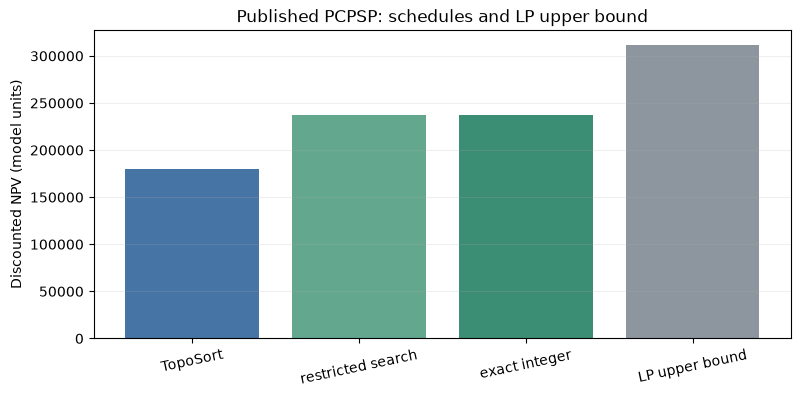

In [9]:
# Compare feasible schedules and the upper bound on one axis.
labels = ['TopoSort', 'restricted search', 'exact integer', 'LP upper bound']
values = [toposort_plan.npv, local_score, scored_npv, relaxation.bound]
colors = ['#4674a5', '#63a88e', '#3b8d73', '#8d969f']
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(labels, values, color=colors)
ax.set(title='Published PCPSP: schedules and LP upper bound',
       ylabel='Discounted NPV (model units)')
ax.tick_params(axis='x', rotation=12)
ax.grid(axis='y', alpha=0.2)
plt.show()

The bars show three feasible schedules and the relaxed upper bound. TopoSort-to-optimum is the heuristic improvement opportunity; optimum-to-LP is fractional relaxation slack. A restricted heuristic matching the optimum on this one seed remains empirical, while the binary solver's proof status is the basis for exactness.

The next chart switches from objective value to assignment pattern. It uses the same period and destination decisions for the baseline and the proven optimum, so changes in block count can be read as a model consequence rather than a different input.

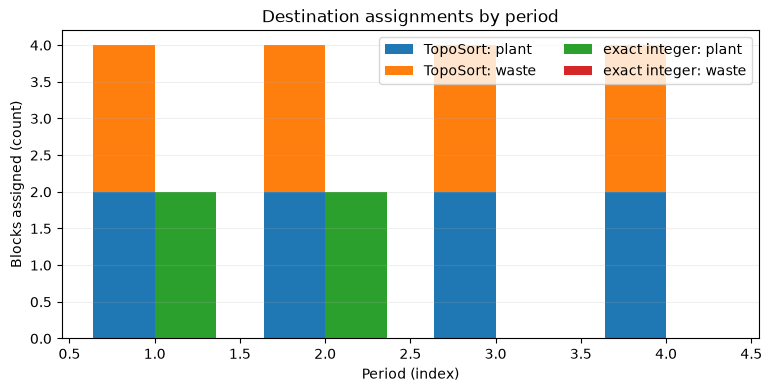

In [10]:
# Compare how the heuristic and exact plans route blocks over time.
periods = np.arange(1, instance.pcpsp.n_periods + 1)
fig, ax = plt.subplots(figsize=(9, 4))
width = 0.36
for offset, plan, name in [(-width / 2, toposort_plan, 'TopoSort'),
                           (width / 2, exact_plan, 'exact integer')]:
    plant_counts = [int(np.sum((plan.period_of_block == t) &
                               (plan.destination_of_block == 1)))
                    for t in range(instance.pcpsp.n_periods)]
    waste_counts = [int(np.sum((plan.period_of_block == t) &
                               (plan.destination_of_block == 0)))
                    for t in range(instance.pcpsp.n_periods)]
    ax.bar(periods + offset, plant_counts, width, label=f'{name}: plant')
    ax.bar(periods + offset, waste_counts, width, bottom=plant_counts,
           label=f'{name}: waste')
ax.set(title='Destination assignments by period', xlabel='Period (index)',
       ylabel='Blocks assigned (count)')
ax.legend(ncol=2)
ax.grid(axis='y', alpha=0.2)
plt.show()

The grouped bars count assignments by destination and period for the constructive and exact plans. They make the scheduling trade-off visible, but counts are not tonnes or cash flow. A lower block count can still give a higher NPV when capacities, destination economics and discounting favor a smaller set of blocks.

## Results

**Answer:** the full binary solver proved an exact NPV of 237344.67, above TopoSort at 179593.14 and equal to restricted local search at 237344.67; the LP upper bound was 311484.31. The comparison separates feasible-plan improvement from relaxation slack. The exact claim applies only to this 48-block encoded instance.

The result section reports the exact solver's quoted objective and cross-checks it against the package scorer and the other methods.

In [11]:
# Print the measured results quoted above.
print(f'exact={scored_npv:.2f}; toposort={toposort_plan.npv:.2f}; '
      f'local={local_score:.2f}; bound={relaxation.bound:.2f}')

exact=237344.67; toposort=179593.14; local=237344.67; bound=311484.31


## Summary

The full binary model proves 237344.67 for this seeded PCPSP instance; TopoSort returns 179593.14, restricted local search reaches the same optimum here, and the LP upper bound is 311484.31. The proof comes from the full solver's optimal status. It applies only to these 48 blocks, capacities, destinations and economic values.

The bars answer two questions. The difference between TopoSort and the proven optimum shows the value captured by improving this feasible plan on this seed. The difference between the exact integer objective and LP upper bound shows relaxation slack. A local search result equal to the optimum in this run is a useful empirical observation, not a proof that local search generally finds it. Exactness attaches to the solver's full model result, not to the best-looking bar.

The assignment plot counts plant and waste blocks in each period for TopoSort and the exact optimum. It reveals that the integer optimum can extract fewer blocks while earning more value: the objective is discounted value subject to resource limits, not total block count. The chart contains no tonnes and does not display ore grade, so it cannot replace period resource use or destination cash-flow analysis. It is a structural explanation of the two returned arrays.

The demonstrated optimum is 237344.67 model units on the generated vein and scenario. It is an exact optimum of the encoded 48-block integer model, subject to the solver's numeric conventions. The LP bound of 311484.31 remains higher, because fractional decisions relax integrality. This difference is expected. It does not mean the exact solve failed, nor does the exact schedule imply that the relaxation is tight on larger cases.

The paper's reported cases are not the source of this notebook's numbers. The article supplies formulation context; PhaseFlow's seeded generator supplies the data. MineLib Newman1 is a distinct aggregate-only fixed-destination CPIT benchmark and is excluded from the PCPSP experiment. Blending, stockpiles, geological uncertainty and mine-wide operational constraints are outside this model. The finding is deliberately narrow: on this teaching input, the package solver proves the destination model optimum and the displayed heuristics can be compared against it.

## References

- Jelvez, Morales and Nancel-Penard (2018), destination-aware open-pit scheduling: https://www.delphoslab.cl/Publicaciones/2018/Jelvez_et_al_MPES2018.pdf
- PhaseFlow synthetic instance builder and pipeline: https://github.com/fsantibanezleal/CAOS_PhaseFlow
- PhaseFlow dossier: docs/methodologies/09_destinations.md